# Cell Graph Tokenization

- Creator: Sebastian Birk (sebastian.birk@helmholtz-munich.de).
- Date of Creation: 17.05.2024
- Date of Last Modification: 05.06.2024

## 1. Setup

### 1.1 Import Libraries

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import json
import os
import pickle
import warnings
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import scgpt as scg
import seaborn as sns
import squidpy as sq
import torch
from datasets import load_from_disk
from scipy.stats import spearmanr
from scgpt.model import TransformerModel
from scgpt.tokenizer.gene_tokenizer import GeneVocab
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder
from skmisc.loess import loess

from nichejepa import tokenizers
from nichejepa import utils

/home/aih/sebastian.birk/miniconda3/envs/nichejepa/lib/python3.10/site-packages/scgpt/model/model.py:21: UserWarning: flash_attn is not installed
  warnings.warn("flash_attn is not installed")
/home/aih/sebastian.birk/miniconda3/envs/nichejepa/lib/python3.10/site-packages/scgpt/model/multiomic_model.py:19: UserWarning: flash_attn is not installed
  warnings.warn("flash_attn is not installed")


### 1.2 Run Notebook Setup

In [3]:
warnings.filterwarnings("ignore")
pd.set_option('display.max_columns', None)

### 1.3 Configure Paths and Create Directories

In [4]:
# Define paths
st_data_folder_path = "../datasets/st_data" # spatially resolved transcriptomics data
st_data_bronze_folder_path = f"{st_data_folder_path}/bronze"
st_data_silver_folder_path = f"{st_data_folder_path}/silver"
st_data_gold_folder_path = f"{st_data_folder_path}/gold"
tokenizer = "cell_graph_tokenizer"
tokenizer_folder_path = f"../datasets/tokenizer/{tokenizer}"
results_folder_path = "../datasets/results"
geneformer_token_dictionary_file = f"../datasets/tokenizer/geneformer_token_dictionary.pkl"
# dataset_cache_file = "../datasets/scgpt_gene_embeddings"
scgpt_model_dir = Path("../scgpt/pretrained_model")
scgpt_model_config_file = scgpt_model_dir / "args.json"
scgpt_model_file = scgpt_model_dir / "best_model.pt"
scgpt_vocab_file = scgpt_model_dir / "vocab.json"
scgpt_metadata_file = Path("../scgpt/metadata/gene_info.csv")

## 2. Tokenization

In [5]:
# Define dataset
dataset_name = "nanostring_cosmx_human_brain"
#dataset_name = "xenium_human_brain_cancer"

In [6]:
os.makedirs(f"{tokenizer_folder_path}/{dataset_name}", exist_ok=True)

# Set dataset-specific paths and parameters
gene_means_dictionary_file = f"{tokenizer_folder_path}/{dataset_name}/gene_means_dictionary.pkl"
gene_nzmedians_dictionary_file = f"{tokenizer_folder_path}/{dataset_name}/gene_nzmedians_dictionary.pkl"
gene_logmeans_dictionary_file = f"{tokenizer_folder_path}/{dataset_name}/gene_logmeans_dictionary.pkl"
nichejepa_token_dictionary_file = f"{tokenizer_folder_path}/{dataset_name}/token_dictionary.pkl"

input_directory = f"{st_data_silver_folder_path}/{dataset_name}"
output_directory = f"{st_data_gold_folder_path}/{tokenizer}/{dataset_name}"
if dataset_name == "nanostring_cosmx_human_brain":
    custom_attr_name_dict = {"cell_type": "cell_types",
                             "niche_type": "niche_types"}
    label_cats = ["cell_types", "niche_types"]
elif dataset_name == "xenium_human_brain_cancer":
    custom_attr_name_dict = {"cluster": "cluster"}
    label_cats = ["cluster"]

### 2.1 Create Token Dictionary

In [22]:
# Load data
adata = sc.read_h5ad(f"{st_data_silver_folder_path}/{dataset_name}/{dataset_name}.h5ad")

# Filter cells that did not pass QC
if "filter_pass" in adata.obs.columns:
    filter_pass_idx = np.where([filter_pass == 1 for filter_pass in adata.obs["filter_pass"]])[0]
else:
    filter_pass_idx = np.array([i for i in range(adata.shape[0])])
adata = adata[filter_pass_idx]

# Compute spatial neighborhood graph based on Visium spot diameter of 55 microns
sq.gr.spatial_neighbors(adata,
                        coord_type="generic",
                        spatial_key="spatial",
                        radius=27.5,
                        )

In [23]:
### Create token dict for nichejepa ###

# Load geneformer token dict to get protein-coding and miRNA genes
with open(geneformer_token_dictionary_file, "rb") as f:
    token_dict = pickle.load(f)

# Add cls token
def insert_at_index(d, index, key, value):
    items = list(d.items())
    items.insert(index, (key, value))
    new_d = dict(items)
    return new_d
token_dict = insert_at_index(token_dict, 2, "<cls>", 2)

# Remove genes not in dataset
gene_list = adata.var["ensembl_id"].tolist()
token_dict_copy = token_dict.copy()
for token in token_dict_copy.keys():
    if "ENS" in token and token not in gene_list:
        del(token_dict[token])
del(token_dict_copy)

# Separate gene tokens into cell and neighborhood tokens
new_token_dict = {
    (key if "ENS" in key else key): value
    for value, key in enumerate(token_dict.keys())}

# Write to disk
with open(nichejepa_token_dictionary_file, "wb") as file:
    pickle.dump(new_token_dict, file)

In [24]:
# Load vocab
with open(nichejepa_token_dictionary_file, "rb") as file:
    token_dict = pickle.load(file)

token_dict_reverse = {value: key for key, value in token_dict.items()}

In [25]:
# NicheJEPA token dict
len(token_dict)

6034

In [26]:
# First cell gene token
token_dict["ENSG00000000938"]

3

### 2.2 Compute Normalization Factors for Gene Counts

Corpus means, non-zero medians, or log means are used depending on the 'norm_method' specified in the CellGraphRankTokenizer (check source code).

In [27]:
# Compute Corpus Means, Regularized Standard Deviations, and Non-zero Medians for
# Cell and Neighborhood Genes
for norm_factor in ["read_depth", "cell_area"]:
    # Load data
    adata = sc.read_h5ad(f"{st_data_silver_folder_path}/{dataset_name}/{dataset_name}.h5ad")
    if type(adata.X) == sp._csr.csr_matrix:
        adata.X = adata.X.toarray()

    # Filter cells that did not pass QC
    if "filter_pass" in adata.obs.columns:
        filter_pass_idx = np.where([filter_pass == 1 for filter_pass in adata.obs["filter_pass"]])[0]
    else:
        print(f"adata has no column 'filter_pass'; utilizing all cells.")
        filter_pass_idx = np.array([i for i in range(adata.shape[0])])
    adata = adata[filter_pass_idx]
    
    if norm_factor == "read_depth":
        # Normalize cell gene counts by read depth
        adata.X = adata.X / adata.X.sum(1).reshape(-1, 1) * 10000
    elif norm_factor == "cell_area":
        # Normalize cell gene counts by cell area
        adata.X = adata.X / adata.obs["cell_area"].values.reshape(-1, 1)
        
    # Compute means, vars, and non-zero medians of
    # read-depth or cell-area normalized cell gene counts
    gene_means = np.mean(adata.X, axis=0)
    masked_data = np.ma.masked_equal(adata.X, 0)
    gene_nzmedians = np.ma.mean(masked_data, axis=0)
    gene_nzmedians = gene_nzmedians.filled(0)

    sc.pp.log1p(adata)
    gene_logmeans = np.mean(adata.X, axis=0)

    gene_logmeans = np.array(gene_logmeans).reshape(-1)
    gene_nzmedians = np.array(gene_nzmedians).reshape(-1)
    gene_means = np.array(gene_means).reshape(-1)
 
    # Create norm factor dictionaries for tokenizer and store on disk
    gene_means_dict = {}
    gene_nzmedians_dict = {}
    gene_logmeans_dict = {}
    
    for (gene,
         gene_mean,
         gene_nzmedian,
         gene_logmean,) in zip(
            adata.var["ensembl_id"].values,
            gene_means,
            gene_nzmedians,
            gene_logmeans):
        gene_means_dict[gene] = gene_mean
        gene_nzmedians_dict[gene] = gene_nzmedian
        gene_logmeans_dict[gene] = gene_logmean
    
    with open(gene_means_dictionary_file.replace("gene", f"gene_{norm_factor}"), "wb") as file:
        pickle.dump(gene_means_dict, file)
    with open(gene_nzmedians_dictionary_file.replace("gene", f"gene_{norm_factor}"), "wb") as file:
        pickle.dump(gene_nzmedians_dict, file)
    with open(gene_logmeans_dictionary_file.replace("gene", f"gene_{norm_factor}"), "wb") as file:
        pickle.dump(gene_logmeans_dict, file)

adata has no column 'filter_pass'; utilizing all cells.
adata has no column 'filter_pass'; utilizing all cells.


In [28]:
values = []
for key, value in gene_means_dict.items():
    values.append(value)

np.mean(values)

7.847695360502145e-09

### 2.3 Run Tokenizer

In [36]:
# Tokenize data with different normalization methods
for model_input_size in [#16,
                         #32,
                         #64,
                         2048
                        ]:
    for norm_method in [#"analytic_pearson_residuals",
                        #"mean",
                        #"nzmedian",
                        #"seurat_v3",
                        "shifted_logmean",
                        #"shifted_log",
    ]:
        if norm_method == "analytic_pearson_residuals":
            output_file_prefix = f"{dataset_name}_{norm_method}_{model_input_size}"
    
            tk = tokenizers.CellGraphRankTokenizer(
                    model_input_size=model_input_size,
                    norm_method=norm_method,
                    gene_means_file=gene_means_dictionary_file.replace("gene", f"gene_{norm_factor}"),
                    gene_nzmedians_file=gene_nzmedians_dictionary_file.replace("gene", f"gene_{norm_factor}"),
                    gene_logmeans_file=gene_logmeans_dictionary_file.replace("gene", f"gene_{norm_factor}"),
                    token_dictionary_file=nichejepa_token_dictionary_file,
                    custom_attr_name_dict=custom_attr_name_dict)
    
            tk.tokenize_data(input_directory=input_directory,
                             output_directory=output_directory,
                             output_file_prefix=output_file_prefix)
            
        elif norm_method != "analytic_pearson_residuals":
            for norm_factor in ["read_depth",
                                "cell_area"
                               ]:
                output_file_prefix = f"{dataset_name}_{norm_factor}_{norm_method}_{model_input_size}"
    
                tk = tokenizers.CellGraphRankTokenizer(
                        model_input_size=model_input_size,
                        norm_method=norm_method,
                        gene_means_file=gene_means_dictionary_file.replace("gene", f"gene_{norm_factor}"),
                        gene_nzmedians_file=gene_nzmedians_dictionary_file.replace("gene", f"gene_{norm_factor}"),
                        gene_logmeans_file=gene_logmeans_dictionary_file.replace("gene", f"gene_{norm_factor}"),
                        token_dictionary_file=nichejepa_token_dictionary_file,
                        custom_attr_name_dict=custom_attr_name_dict)
                    
                tk.tokenize_data(input_directory=input_directory,
                                 output_directory=output_directory,
                                 output_file_prefix=output_file_prefix)

Tokenizing '../datasets/st_data/silver/nanostring_cosmx_human_brain/nanostring_cosmx_human_brain.h5ad'...
Filtering cells.
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood graph.
Normalizing gene expression counts.
Retrieving tokens for index cell and adding cell metadata.
Retrieving tokens for neighborhood cells.
Creating Hugging Face dataset...


Map:   0%|          | 0/188686 [00:00<?, ? examples/s]

Saving the dataset (0/7 shards):   0%|          | 0/188686 [00:00<?, ? examples/s]

Tokenizing '../datasets/st_data/silver/nanostring_cosmx_human_brain/nanostring_cosmx_human_brain.h5ad'...
Filtering cells.
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood graph.
Normalizing gene expression counts.
Retrieving tokens for index cell and adding cell metadata.
Retrieving tokens for neighborhood cells.
Creating Hugging Face dataset...


Map:   0%|          | 0/188686 [00:00<?, ? examples/s]

Saving the dataset (0/7 shards):   0%|          | 0/188686 [00:00<?, ? examples/s]

### 2.4 Evaluate Tokenizer

In [7]:
# Load tokenized dataset
norm_factor = "read_depth"
norm_method = "seurat_v3" # "seurat_v3", "shifted_log"
model_input_size = 2048
tokenized_data_folder_path = f"{st_data_gold_folder_path}/{tokenizer}/{dataset_name}/{dataset_name}_{norm_factor}_{norm_method}_{model_input_size}.dataset"
dataset = load_from_disk(tokenized_data_folder_path, keep_in_memory=True)

In [8]:
dataset

Dataset({
    features: ['gene_tokens', 'cell_types', 'niche_types', 'cell_pos_tokens', 'gene_pos_tokens', 'input_ids'],
    num_rows: 188686
})

In [9]:
# Check number of unique top genes
top_n = 5
all_top_gene_tokens = []
for gene_tokens in dataset["gene_tokens"]:
    all_top_gene_tokens.extend(gene_tokens[:top_n])

print(len(set(all_top_gene_tokens)))

5907


#### 2.4.1 Cell Classification

In [7]:
# Load vocab
with open(nichejepa_token_dictionary_file, "rb") as file:
    token_dict = pickle.load(file)

token_dict_reverse = {value: key for key, value in token_dict.items()}

In [8]:
# Get classification tokens
def get_classification_tokens(example, top_n):
    neighbor_cell_token_start_idx = [example["cell_pos_tokens"].index(i)
                                     for i in range(0, max(example["cell_pos_tokens"]) + 1)] # includes index cell
    example[f"top_{top_n}_neighbor_cell_token_ids"] = []
    for n in range(top_n):
        neighbor_cell_token_ids = []
        for i in neighbor_cell_token_start_idx:
            neighbor_cell_token_ids.append(example["gene_tokens"][i+n])
        example[f"top_{top_n}_neighbor_cell_token_ids"].append(neighbor_cell_token_ids)
        
    example[f"top_{top_n}_neighbor_cell_tokens"] = [[
        token_dict_reverse[token_id]
        for token_id in neighbor_cell_tokens]
        for neighbor_cell_tokens in example[f"top_{top_n}_neighbor_cell_token_ids"]]  

    example[f"top_{top_n}_index_cell_tokens"] = [
        token_dict_reverse[token_id]
        for token_id in example["gene_tokens"][:top_n]]

    return example

##### 2.4.1.1 scGPT

Task: cell type classification using scGPT embedded top ranked genes.

In [9]:
### Get scGPT gene embeddings for each gene Ensembl id ###

# Set config
pad_token = "<pad>"
special_tokens = [pad_token, "<cls>", "<eoc>"]
pad_value = -2
n_input_bins = 51

# Get vocab
scgpt_vocab = GeneVocab.from_file(scgpt_vocab_file)
for s in special_tokens:
    if s not in scgpt_vocab:
        scgpt_vocab.append_token(s)

# Retrieve model parameters from config files
with open(scgpt_model_config_file, "r") as f:
    model_configs = json.load(f)
print(f"Resume model from {scgpt_model_file}, the model args will override the "
      f"config {scgpt_model_config_file}.")
embsize = model_configs["embsize"]
nhead = model_configs["nheads"]
d_hid = model_configs["d_hid"]
nlayers = model_configs["nlayers"]
n_layers_cls = model_configs["n_layers_cls"]

# Initialize model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ntokens = len(scgpt_vocab)  # size of vocabulary
model = TransformerModel(ntokens,
                         embsize,
                         nhead,
                         d_hid,
                         nlayers,
                         vocab=scgpt_vocab,
                         pad_value=pad_value,
                         n_input_bins=n_input_bins,)

try:
    model.load_state_dict(torch.load(scgpt_model_file))
    print(f"Loading all model params from {scgpt_model_file}")
except:
    model_dict = model.state_dict()
    pretrained_dict = torch.load(scgpt_model_file)
    pretrained_dict = {k: v
                       for k, v in pretrained_dict.items()
                       if k in model_dict and v.shape == model_dict[k].shape}
    for k, v in pretrained_dict.items():
        print(f"Loading params {k} with shape {v.shape}")
        model_dict.update(pretrained_dict)
        model.load_state_dict(model_dict)
model.to(device)

# Create mapping from Ensembl id to scGPT token id
gene2idx = scgpt_vocab.get_stoi()

metadata_df = pd.read_csv(scgpt_metadata_file)

ensemblid_mapping = dict(zip(metadata_df["feature_name"], metadata_df["feature_id"]))
ensemblid2idx = {ensemblid_mapping[k]: v for k, v in gene2idx.items() if k in ensemblid_mapping}

# Retrieve the data-independent gene embeddings from scGPT
gene_ids = np.array([id for id in ensemblid2idx.values()])
gene_embeddings = model.encoder(torch.tensor(gene_ids, dtype=torch.long).to(device))
gene_embeddings = gene_embeddings.detach().cpu().numpy()

# Store gene embeddings with Ensembl id
emsemblid_embedding_mapping = {}
for i, (key, val) in enumerate(ensemblid2idx.items()):
    emsemblid_embedding_mapping[key] = gene_embeddings[i, :]

Resume model from ../scgpt/pretrained_model/best_model.pt, the model args will override the config ../scgpt/pretrained_model/args.json.
Loading params encoder.embedding.weight with shape torch.Size([60697, 512])
Loading params encoder.enc_norm.weight with shape torch.Size([512])
Loading params encoder.enc_norm.bias with shape torch.Size([512])
Loading params value_encoder.linear1.weight with shape torch.Size([512, 1])
Loading params value_encoder.linear1.bias with shape torch.Size([512])
Loading params value_encoder.linear2.weight with shape torch.Size([512, 512])
Loading params value_encoder.linear2.bias with shape torch.Size([512])
Loading params value_encoder.norm.weight with shape torch.Size([512])
Loading params value_encoder.norm.bias with shape torch.Size([512])
Loading params transformer_encoder.layers.0.self_attn.out_proj.weight with shape torch.Size([512, 512])
Loading params transformer_encoder.layers.0.self_attn.out_proj.bias with shape torch.Size([512])
Loading params tran

In [10]:
top_n = 10
n_tokens_per_cell = 64
model_input_size = 2048
scores = []

for norm_method in ["analytic_pearson_residuals",
                    "mean",
                    "nzmedian",
                    "seurat_v3",
                    "shifted_logmean",
                    "shifted_log",
]:
    if norm_method == "analytic_pearson_residuals":
        normalization = f"{norm_method}"
    if norm_method != "analytic_pearson_residuals":
        norm_factor = "cell_area" # "read_depth", "cell_area"
        normalization = f"{norm_factor}_{norm_method}"
    
    output_file_prefix = f"{dataset_name}_{normalization}_{model_input_size}"
    tokenized_data_folder_path = f"{st_data_gold_folder_path}/{tokenizer}/{dataset_name}/{output_file_prefix}.dataset"
    dataset = load_from_disk(tokenized_data_folder_path, keep_in_memory=True)
    dataset = dataset.map(get_classification_tokens,
                          fn_kwargs={"top_n": top_n},
                          #cache_file_name=dataset_cache_file,
                         )

    X_cell = np.array(
        [[emsemblid_embedding_mapping[token] for token in sequence] for
         sequence in dataset[f"top_{top_n}_index_cell_tokens"]])
    X_cell = X_cell.reshape(X_cell.shape[0], -1)

    X_neighbor_cells = np.array(
        [[np.mean([emsemblid_embedding_mapping[token] for token in neighbor_cell_tokens], axis=0) for
          neighbor_cell_tokens in sequence] for sequence in dataset[f"top_{top_n}_neighbor_cell_tokens"]])
    X_neighbor_cells = X_neighbor_cells.reshape(X_neighbor_cells.shape[0], -1)

    for token_type in ["cell", "neighbor_cells"]:
        for label_cat in label_cats:
            label_encoder = LabelEncoder()
            labels = np.array(
                label_encoder.fit_transform(dataset[label_cat]))

            for random_state in range(10):

                np.random.seed(random_state)
    
                indices = np.arange(X_cell.shape[0])
                np.random.shuffle(indices)
                num_train = int(0.8 * len(indices))
                train_indices = indices[:num_train]
                test_indices = indices[num_train:]
                labels_train = labels[train_indices]
                labels_test = labels[test_indices]
                if token_type == "cell":
                    X = X_cell
                else:
                    X = X_neighbor_cells
                X_train = X[train_indices]
                X_test = X[test_indices]
            
                lr_clf = LogisticRegression()
                lr_clf.fit(X_train, labels_train)
                train_score = lr_clf.score(X_train, labels_train)
                test_score = lr_clf.score(X_test, labels_test)
                scores.append({"tokenizer": tokenizer,
                               "normalization": normalization,
                               "token_type": token_type,
                               "clf_task": label_cat,
                               "random_state": random_state,
                               "clf_category": "train",
                               "score": train_score})
                scores.append({"tokenizer": tokenizer,
                               "normalization": normalization,
                               "token_type": token_type,
                               "clf_task": label_cat,
                               "random_state": random_state,
                               "clf_category": "test",
                               "score": test_score})

                scores_df = pd.DataFrame(scores)
                scores_df.to_csv(f"{results_folder_path}/{tokenizer}/{dataset_name}/clf_scores_scgpt.csv", index=False)

Map:   0%|          | 0/188686 [00:00<?, ? examples/s]

Map:   0%|          | 0/188686 [00:00<?, ? examples/s]

Map:   0%|          | 0/188686 [00:00<?, ? examples/s]

Map:   0%|          | 0/188686 [00:00<?, ? examples/s]

Map:   0%|          | 0/188686 [00:00<?, ? examples/s]

In [16]:
df1 = pd.read_csv("../datasets/results/cell_graph_tokenizer/nanostring_cosmx_human_brain/clf_scores_scgpt_1.csv")
df2 = pd.read_csv("../datasets/results/cell_graph_tokenizer/nanostring_cosmx_human_brain/clf_scores_scgpt_2.csv")
df = pd.concat([df1, df2], axis=0)
df.to_csv("../datasets/results/cell_graph_tokenizer/nanostring_cosmx_human_brain/clf_scores_scgpt.csv", index=False)

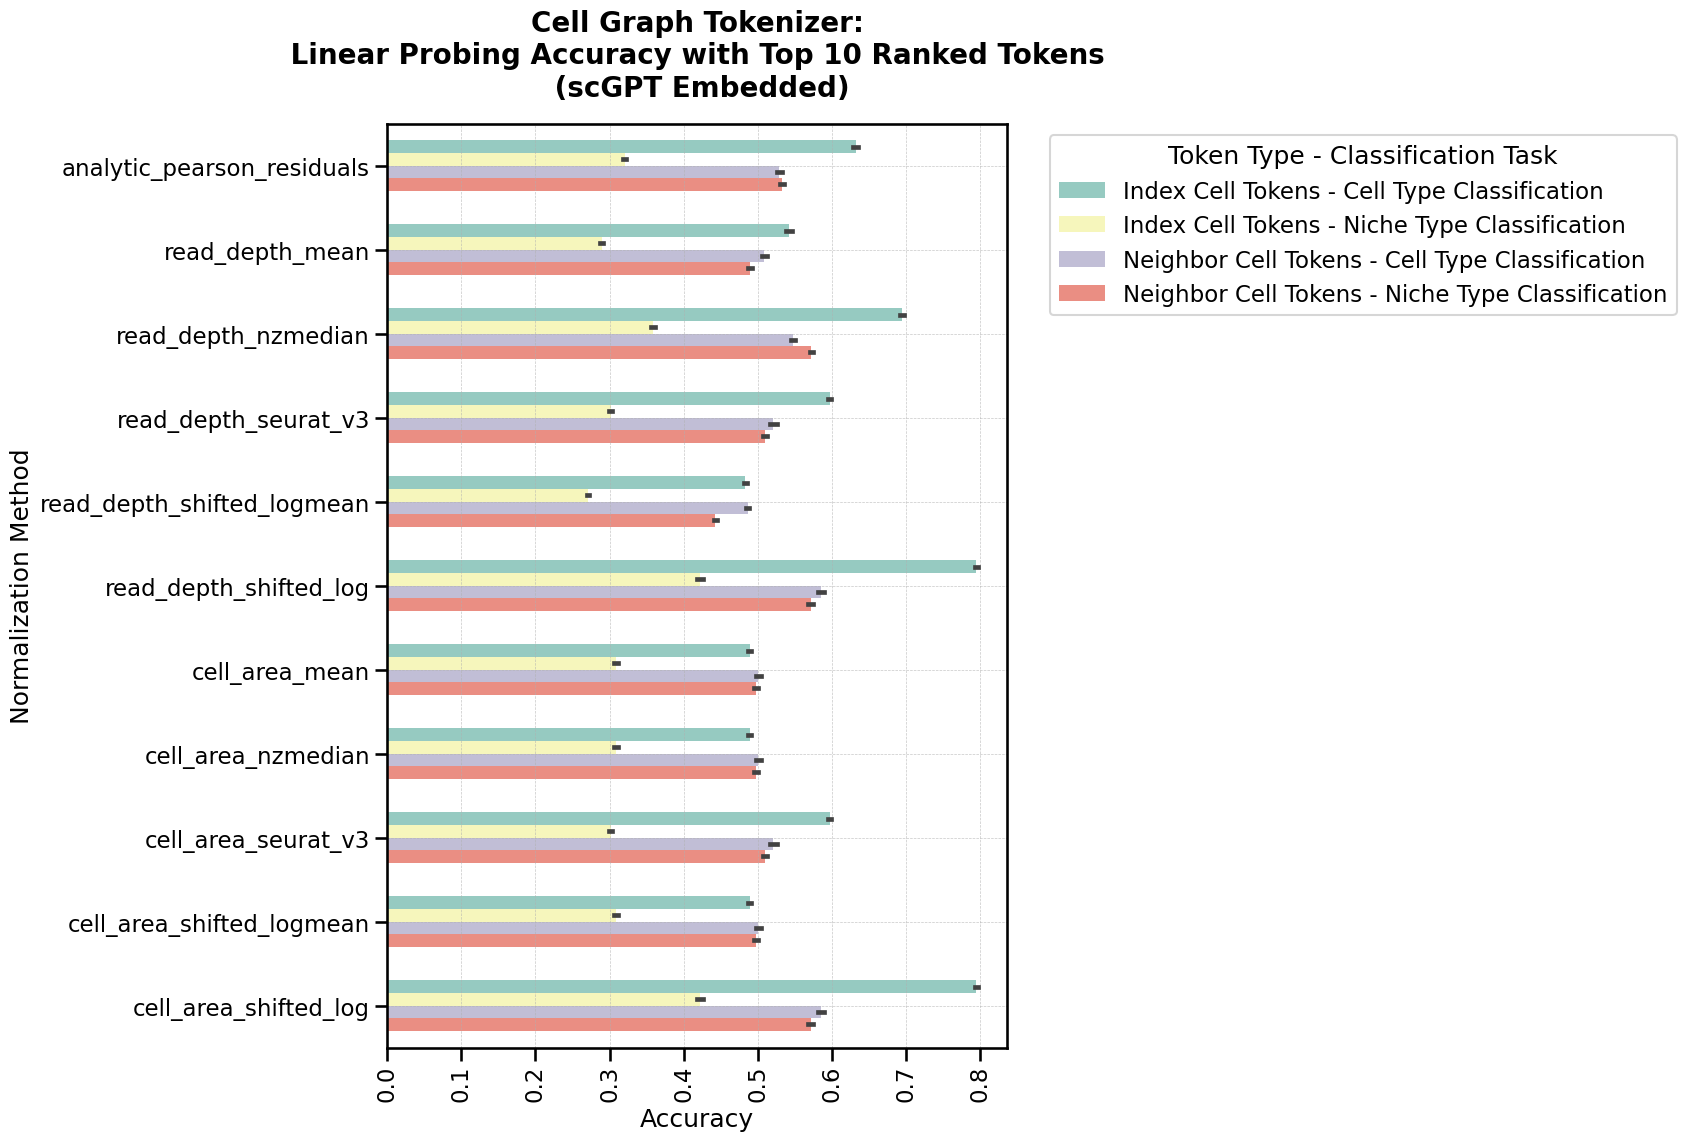

In [37]:
### Visualize results ###

def capitalize_after_space(s):
    return " ".join(word.capitalize() for word in s.split("_"))

df = pd.read_csv(f"{results_folder_path}/{tokenizer}/{dataset_name}/clf_scores_scgpt.csv")


# Only keep test scores
df = df[(df["clf_category"] == "test")]

# Rename token types
df["token_type"] = df["token_type"].replace(
    {"cell": "Index Cell Tokens", "neighbor_cells": "Neighbor Cell Tokens"})

# Rename classification tasks
df["clf_task"] = df["clf_task"].replace(
    {"cell_types": "Cell Type Classification", "niche_types": "Niche Type Classification"})

# Create a combined hue for clf_task and clf_category
df["token_task"] = df["token_type"] + " - " + df["clf_task"]

# Plot
plt.figure(figsize=(8, 12))
sns.barplot(
    x="score", y="normalization", hue="token_task", data=df, ci="sd", 
    palette="Set3", orient="h", width=0.6
)

# Adjusting the spacing between the bars
# You can control the spacing by setting a custom height for each bar
unique_normalizations = df["normalization"].unique()
unique_token_tasks = df["token_task"].unique()
spacing = 0.1 * len(unique_token_tasks)  # Adjust this value to increase/decrease space

plt.xticks(rotation=90)  # Rotate x-axis labels if needed
plt.title(f"{capitalize_after_space(tokenizer)}:"
          "\n Linear Probing Accuracy with Top 10 Ranked Tokens \n (scGPT Embedded)",
          fontsize=20,
          fontweight="bold",
          pad=20)
plt.xlabel("Accuracy")
plt.ylabel("Normalization Method")
plt.legend(title="Token Type - Classification Task", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, which='both', linestyle='--', linewidth=0.5, alpha=0.7)

plt.savefig(f"{results_folder_path}/{tokenizer}/{dataset_name}/clf_scores_scgpt.svg", bbox_inches="tight")
plt.show()

In [ ]:
i = 0
# Get sorted indices of neighbor cells based on distance to index cell
row_start = adata.obsp["spatial_distances"].indptr[i]
row_end = adata.obsp["spatial_distances"].indptr[i+1]
row_data = adata.obsp["spatial_distances"].data[row_start:row_end]
sorted_indices = np.argsort(row_data)
row_data
adata.obsp["spatial_connectivities"][i].nonzero()[1][sorted_indices][0]

In [ ]:
adata.obsp["spatial_connectivities"][i].nonzero()[1][sorted_indices][0]

#### 2.4.2 Neighborhood Ranking

In [ ]:
# Log transform counts as per https://squidpy.readthedocs.io/en/stable/notebooks/tutorials/tutorial_vizgen_mouse_liver.html#autocorrelation-moran-s-i-score
sc.pp.log1p(adata)

In [ ]:
# Compute spatial autocorrelation score
sq.gr.spatial_autocorr(adata, mode="moran")
if "I" in adata.var.columns:
    del(adata.var["I"])
adata.var = adata.var.join(adata.uns["moranI"][["I"]], how="left")

In [ ]:
# Get most and least autocorrelated genes
num_view = 12
top_autocorr = (
    adata.uns["moranI"]["I"].sort_values(ascending=False).head(num_view).index.tolist())
bot_autocorr = (
    adata.uns["moranI"]["I"].sort_values(ascending=True).head(num_view).index.tolist())

In [ ]:
# Plot most autocorrelated genes
sq.pl.spatial_scatter(
    adata, color=top_autocorr, size=20, cmap="Reds", figsize=(5, 5), shape=None)

In [ ]:
# Plot least autocorrelated genes
sq.pl.spatial_scatter(
    adata, color=bot_autocorr, size=20, cmap="Reds", img=False, figsize=(5, 5), shape=None)

In [ ]:
rank_thresh = 1024

# Sum up ranks for each cell gene token
gene_rank_sums = {}

for token in token_dict.keys():
    if "cell" in token and "ENS" in token:
        gene_rank_sums[token.replace("_cell", "")] = 0

for i, row in enumerate(adata.obsm["gene_token_ranking"]):
    for rank, token_id in enumerate(row[:rank_thresh]):
        if token_id != 0:
            gene_rank_sums[
            token_dict_reverse[token_id].replace("_cell", "")] += (rank_thresh - rank)

gene_rank_file = f"{results_folder_path}/{dataset_name}/gene_rank_sums_{norm_factor}_{norm_method}.pkl"

with open(gene_rank_file, "wb") as file:
    pickle.dump(gene_rank_sums, file)

# Sum up ranks for each neighborhood gene token
neighborhood_gene_rank_sums = {}

for token in token_dict.keys():
    if "neighborhood" in token and "ENS" in token:
        neighborhood_gene_rank_sums[token.replace("_neighborhood", "")] = 0

for i, row in enumerate(adata.obsm["neighborhood_gene_token_ranking"]):
    for rank, token_id in enumerate(row[:rank_thresh]):
        if token_id != 0:
            neighborhood_gene_rank_sums[
            token_dict_reverse[token_id].replace("_neighborhood", "")] += (rank_thresh - rank)

neighborhood_gene_rank_file = f"{results_folder_path}/{dataset_name}/neighborhood_gene_rank_sums_{norm_factor}_{norm_method}.pkl"

with open(neighborhood_gene_rank_file, "wb") as file:
    pickle.dump(neighborhood_gene_rank_sums, file)

adata.var["neigborhood_gene_rank_sums"] = adata.var["ensembl_id"].map(neighborhood_gene_rank_sums).fillna(0)
adata.var["gene_rank_sums"] = adata.var["ensembl_id"].map(gene_rank_sums).fillna(0)

correlation, p_value = spearmanr(adata.var["neigborhood_gene_rank_sums"],
                                 adata.var["I"])
print("Spearman Correlation Coefficient Neighborhood:", correlation)
print("P-value:", p_value)

correlation, p_value = spearmanr(adata.var["gene_rank_sums"],
                                 adata.var["I"])
print("Spearman Correlation Coefficient Cell:", correlation)
print("P-value:", p_value)

### 2.5 Miscellaneous

In [ ]:
print(np.var([2, 4, 8]))
print(np.var([20, 40, 80]))
print(np.var([2, 4, 8] - np.array([np.mean([2, 20]), np.mean([4, 40]), np.mean([8, 80])])))
print(np.var([20, 40, 80] - np.array([np.mean([2, 20]), np.mean([4, 40]), np.mean([8, 80])])))

In [ ]:
print(np.var(np.log([2, 4, 8])))
print(np.var(np.log([20, 40, 80])))
print(np.var(np.log([2, 4, 8]) - np.array([np.mean(np.log([2, 20])), np.mean(np.log([4, 40])), np.mean(np.log([8, 80]))])))
print(np.var(np.log([20, 40, 80]) - np.array([np.mean(np.log([2, 20])), np.mean(np.log([4, 40])), np.mean(np.log([8, 80]))])))

In [ ]:
print(np.var(np.log([2, 4, 8])))
print(np.var(np.log([20, 40, 80])))
print(np.var(np.log([2, 4, 8]) / np.array([np.mean(np.log([2, 20])), np.mean(np.log([4, 40])), np.mean(np.log([8, 80]))])))
print(np.var(np.log([20, 40, 80]) / np.array([np.mean(np.log([2, 20])), np.mean(np.log([4, 40])), np.mean(np.log([8, 80]))])))

In [ ]:
i = 12
# Get sorted indices of neighbor cells based on distance to index cell
row_start = adata.obsp["spatial_distances"].indptr[i]
row_end = adata.obsp["spatial_distances"].indptr[i+1]
row_data = adata.obsp["spatial_distances"].data[row_start:row_end]
sorted_indices = np.argsort(row_data)
row_data

adata.obsp["spatial_connectivities"][i].nonzero()[1][sorted_indices][0]
adata.obsp["spatial_connectivities"][i].nonzero()[1]
dataset["gene_tokens"][i][64:]
dataset["gene_tokens"][adata.obsp["spatial_connectivities"][i].nonzero()[1][sorted_indices][0]]

In [ ]:
tk = tokenizers.CellGraphRankTokenizer(
        model_input_size=model_input_size,
        norm_method=norm_method,
        gene_means_file=gene_means_dictionary_file.replace("gene", f"gene_{norm_factor}"),
        gene_reg_stds_file=gene_reg_stds_dictionary_file.replace("gene", f"gene_{norm_factor}"),
        gene_nzmedians_file=gene_nzmedians_dictionary_file.replace("gene", f"gene_{norm_factor}"),
        gene_logmeans_file=gene_logmeans_dictionary_file.replace("gene", f"gene_{norm_factor}"),
        token_dictionary_file=nichejepa_token_dictionary_file,
        custom_attr_name_dict=custom_attr_name_dict)

norm_factor = "read_depth"
norm_method = "seurat_v3" # "seurat_v3", "shifted_log"
model_input_size = 2048

adata = ad.read_h5ad(f"{st_data_silver_folder_path}/{dataset_name}/{dataset_name}.h5ad")

# Filter cells that did not pass QC
if "filter_pass" in adata.obs.columns:
    filter_pass_idx = np.where([filter_pass == 1 for filter_pass in adata.obs["filter_pass"]])[0]
else:
    filter_pass_idx = np.array([i for i in range(adata.shape[0])])
adata = adata[filter_pass_idx]

# Compute spatial neighborhood graph based on Visium spot diameter of 55 microns
sq.gr.spatial_neighbors(adata,
                        coord_type="generic",
                        spatial_key="spatial",
                        radius=27.5,
                        )

if norm_factor == "read_depth":
    # Normalize cell counts
    target_sum = 10_000
    adata.X = adata.X / adata.X.sum(1).reshape(-1, 1) * target_sum

if norm_method == "seurat_v3":
    # Load cell and neighborhood gene corpus means and vars
    with open(gene_means_dictionary_file.replace("gene", f"gene_{norm_factor}"), "rb") as f:
        gene_means_dict = pickle.load(f)
    with open(gene_reg_stds_dictionary_file.replace("gene", f"gene_{norm_factor}"), "rb") as f:
        gene_reg_stds_dict = pickle.load(f)
    
    # Retrieve cell and neighborhood gene means and regularized standard deviations
    gene_means = np.array([gene_means_dict[gene_id] for gene_id in adata.var["ensembl_id"]])
    gene_reg_stds = np.array(
        [gene_reg_stds_dict[gene_id] for gene_id in adata.var["ensembl_id"]]
        )

    # Normalize cell and neighborhood counts
    norm_counts = adata.X - gene_means / gene_reg_stds
elif norm_method == "shifted_log":
    sc.pp.log1p(adata)

    # Retrieve cell and neighborhood gene logmeans
    gene_logmeans = np.array(
        [gene_logmeans_dict[gene_id] for gene_id in adata.var["ensembl_id"]])
    
    # Normalize cell and neighborhood counts
    adata.X = adata.X / gene_logmeans

# Keep only protein-coding and miRNA genes
vocab = list(token_dict.keys())
coding_miRNA_ids = [
    key.split("_")[0] for key in list(vocab) if "ENS" in key]
coding_miRNA_dict = dict(zip(coding_miRNA_ids, [True] * len(vocab)))
coding_miRNA_idx = np.where(
    [coding_miRNA_dict.get(gene_id, False) for gene_id in adata.var["ensembl_id"]])[0]
coding_miRNA_adata = adata[:, coding_miRNA_idx]

cell_idx = 1

gene_idx = np.argmax(coding_miRNA_adata.X[cell_idx])
coding_miRNA_adata.var_names[gene_idx]
#coding_miRNA_adata.X[0, :].toarray()
#coding_miRNA_adata.X[:, gene_idx].toarray()
#np.mean(coding_miRNA_adata.X[:, gene_idx].toarray())

#sc.pp.log1p(coding_miRNA_adata)
sq.pl.spatial_scatter(coding_miRNA_adata,
                      color=coding_miRNA_adata.var_names[gene_idx],
                      shape=None)

# Load tokenized dataset
tokenized_data_folder_path = f"{st_data_gold_folder_path}/{tokenizer}/{dataset_name}/{dataset_name}_{norm_factor}_{norm_method}_{model_input_size}.dataset"
dataset = load_from_disk(tokenized_data_folder_path, keep_in_memory=True)

dataset["gene_tokens"][0]

# Get gene token rankings
tokens = np.array(dataset["input_ids"])
coding_miRNA_adata.obsm["gene_token_ranking"] = tokens[:, 1:]

# Validate
print(coding_miRNA_adata.var["ensembl_id"][gene_idx])
gene_token_idx = coding_miRNA_adata.obsm["gene_token_ranking"][cell_idx][0]
print(token_dict_reverse[gene_token_idx])

In [ ]:
# Get scgpt gene embeddings for NicheJEPA input token ids
def get_scgpt_gene_embeddings(example, top_n):
    neighbor_cell_token_start_idx = [example["cell_pos_tokens"].index(i)
                                     for i in range(0, max(example["cell_pos_tokens"]) + 1)] # includes index cell
    example[f"top_{top_n}_neighbor_cell_token_ids"] = []
    top_n_per_cell = top_n / len(neighbor_cell_token_start_idx)
    if top_n_per_cell > int(top_n_per_cell):
        add_gene_n = top_n - int(top_n_per_cell) * len(neighbor_cell_token_start_idx)
    else:
        add_gene_n = 0
    top_n_per_cell = int(top_n_per_cell)
    for i in neighbor_cell_token_start_idx:
        example[f"top_{top_n}_neighbor_cell_token_ids"].extend(example["gene_tokens"][i:i+top_n_per_cell])
    if add_gene_n > 0:
        for j in range(0, add_gene_n):
            example[f"top_{top_n}_neighbor_cell_token_ids"].extend([example["gene_tokens"][
                                                                    neighbor_cell_token_start_idx[j]+top_n_per_cell+1]])
    
    example[f"top_{top_n}_neighbor_cell_tokens"] = [
        token_dict_reverse[token_id]
        for token_id in example[f"top_{top_n}_neighbor_cell_token_ids"]]  

    example[f"top_{top_n}_index_cell_tokens"] = [
        token_dict_reverse[token_id]
        for token_id in example["gene_tokens"][:top_n]]

    return example